# Comparison of YOLOv11 Variants
The objective of this notebook is to compare the results from the training (and evaluation) phases of every fold of all selected YOLOv11 variants in order to select the best variant for our system


## 0. Preparation

In [1]:
# ===== Models to compare

VARIANTS = ['nano', 'small', 'medium', 'large']
FOLDS = range(5)

MODELS_DIR = '/workspace/models'

## 1. Utility functions

### 1.A Retrieval function
Used to get the path to the model, given the varian and the fold index

In [2]:
# ===== model_directory function

import json
from pathlib import Path

def model_directory(
    variant: str, fold: int, 
    model_type: str = 'yolov11',
    base_path: str = MODELS_DIR
):
    """ 
    Given a target model, it returns the path to that model directory,
    the weights subfolder and the evaluation result subfolder
    """
    
    model_dir = Path(base_path)/ model_type / variant / f'fold_{fold}'

    return model_dir, model_dir/'weights', model_dir/'eval'

### 1.B Statistic function *mean_std_ci*

Function used to get *mean value*, *(sample) standard deviation* and *confidence interval (CI)* for a given set of measurements

---

Mean value $\bar{x}$:
$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

Sample standard deviation $s$:
$$
s = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2}
$$

Confidence interval error $\text{CI}_{err}$:
$$
\text{CI}_{err} = t_{\alpha/2, \, n-1} \cdot \frac{s}{\sqrt{n}}
$$

---

Note that with confidence interval we mean:
$$
\text{CI} = \left[ \bar{x} - \text{CI}_{err}, \,\, \bar{x} + \text{CI}_{err} \right]
$$

In [3]:
# ===== mean_std_ci function

import numpy as np
from scipy.stats import t

def mean_std_ci(values, conf_interval_perc):
    """ 
    Return statistic indexes a list of measurements

    Returns (mean, std_dev, conf_interval)
    """

    # Force to np array
    values = np.array(values)

    # Calculate mean and std
    mean = values.mean()
    std = values.std()

    # Calculate confidence interval
    n = len(values)
    
    if n < 2:
        ci_err = np.nan
    else:

        # alpha is just 1 - CI required
        alpha = 1 - conf_interval_perc

        # t Student value, for given alpha and n
        t_value = t.ppf(1 - alpha / 2, df=n - 1)

        # ci error
        ci_err = t_value * std / np.sqrt(n)

    return mean, std, ci_err

### 1.C Results table construction

In [4]:
# ===== construction of RESULTS_TABLE

RESULTS_TABLE = {}

# Retrieve all results
for variant in VARIANTS:
    
    RESULTS_TABLE[variant] = {}
    
    for fold_idx in FOLDS:
        
        # Get directory
        mod_dir, _, eval_dir = model_directory(variant, fold_idx)

        results_file = eval_dir / "results.json"
        
        if not results_file.is_file():
            print(f"skipping {results_file}")
            continue
            
        with open(results_file, 'r') as f:
            results_json = json.load(f)

        print(f"Loading {variant}/{fold_idx}...")

        RESULTS_TABLE[variant][fold_idx] = {
            "variant": variant,
            "fold": fold_idx,

            # unpack all keys from json obj
            **results_json          
        }


Loading nano/0...
Loading nano/1...
Loading nano/2...
Loading nano/3...
Loading nano/4...
Loading small/0...
Loading small/1...
Loading small/2...
Loading small/3...
Loading small/4...
Loading medium/0...
Loading medium/1...
Loading medium/2...
Loading medium/3...
Loading medium/4...
Loading large/0...
Loading large/1...
Loading large/2...
Loading large/3...
Loading large/4...


### 1.E Plotting function
Generic plotting function, to be used for any purpose

In [5]:
# ===== plot funciton

import os
import re
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

PLOTS_DIR = "comparison_plots"

def plot(
    x_ticks,
    means: np.ndarray,
    cis: np.ndarray,
    line_labels = None,

    colors = None,

    plot__ci_t: bool = True,
    plot__ci_band: bool = True,
    plot__mean_line__marker: str = "o",

    y_bottom=0,
    y_top=None,

    figsize=(8, 5),
    x_margins: float = 0.1,

    x_label: str = None,
    y_label: str = None,
    title: str = None,

    save_png: bool = True,
    save_dir: str = None,
    save_filename: str = None,
    save_dpi: int = 150
):
    """
    Function to plot multiple lines with confidence intervals
    

    Parameters
    ----------
    x_ticks : labels for x axis
    x_label : label for x-axis
    y_label : label for y-axis
    line_labels: label names for every line to plot
    title : title
    
    means : mean values to plot; each row corresponds to one independent curve to plot.
    cis : symmetric confidence interval errors; each row is paired with the corresponding row of means
    colors : color for each line

    plot__ci_t : if True plots error bars
    plot__ci_band : if True, plots a band between consecutive CI

    plot__mean_line__marker : marker stytle for mean points

    figsize : figure size, default=(8, 5)
    y_bottom : lower limit of y-axis. Default = 0
    y_top : upper limit of y-axis. Default = None
    x_margins : default=0.1
    """

    ### PLOT

    # Set figure size
    plt.figure(figsize=figsize)

    # Gets equal spaced x values from 0
    x = np.arange(len(x_ticks))

    # Force means and cis to a 2d array
    #   If multiple lines are given nothing is modified
    #   If single line is given [0,1,2] it forces it to two dimensions: [[0,1,2]]
    means = np.atleast_2d(means)
    cis = np.atleast_2d(cis)

    # Number of lines to draw
    n_lines = means.shape[0]

    # Force name to have length = n_lines

    # if just one line and no line name has been specifed, don't put anything
    # because its meaning is just the plot title
    if n_lines == 1 and (line_labels is None or line_labels == ['']):
        line_labels = ["_nolegend_"]
    else:
        if line_labels is None:
            line_labels = [f"Series {i}" for i in range(n_lines)]
        elif isinstance(line_labels, str):
            line_labels = [line_labels] * n_lines
        if len(line_labels) != n_lines:
            raise ValueError("line_labels array must have same length as number of lines")

    # Force color to have length = n_lines
    if colors is None:
        colors = [None] * n_lines
    elif np.isscalar(colors) or isinstance(colors, str):
        colors = [colors] * n_lines
    if len(colors) != n_lines:
        raise ValueError("colors array must have same length as number of lines")

    # Plot each line
    for i in range(n_lines):

        # Get line means, cis and color
        m = means[i]
        c = cis[i]
        col = colors[i]

        # Plot mean line WITH Confindence interva bars
        if plot__ci_t:
            plt.errorbar(
                x, m,
                yerr=c,
                fmt=plot__mean_line__marker,
                linestyle="--",
                color=col,
                capsize=5,
                linewidth=1,
                label=line_labels[i]
            )
        # Plot mean line WITHOUT Confindence interva bars
        else:
            plt.plot(
                x, m,
                marker=plot__mean_line__marker,
                linestyle="--",
                linewidth=1,
                color=col,
                label=line_labels[i]
            )

        # Plot continuous shaded band between consecutive CI intervals
        if plot__ci_band:
            plt.fill_between(
                x,
                m - c,
                m + c,
                color=col,
                alpha=0.2
            )

    ### Plot resizing and grid
    
    # Y-axis limits
    if y_bottom is not None:
        plt.ylim(bottom=y_bottom)
    if y_top is not None:
        plt.ylim(top=y_top)

    # X axis margins
    plt.margins(x=x_margins)

    # Grid
    plt.grid(visible=True, color="#ddd", linestyle="--", linewidth=0.5)

    ### Text
    
    # X axis values
    plt.xticks(x, x_ticks)

    # Axis labels
    if x_label is not None:
        plt.xlabel(x_label)
    if y_label is not None:
        plt.ylabel(y_label)

    # Plot title
    if title is not None:
        plt.title(title)

    # Legend
    if line_labels != ["_nolegend_"]:
        plt.legend(ncol = max(1, n_lines // 5))
    
    plt.tight_layout()


    ### Save figure as PNG
    if save_png:

        # Use provided directory, otherwise fall back to the default plots folder
        target_dir = save_dir if save_dir is not None else PLOTS_DIR
        os.makedirs(target_dir, exist_ok=True)

        # Build filename: explicit filename > slug from title > timestamp
        if save_filename is not None:
            fname = save_filename
        elif title is not None:
            fname = re.sub(r"[^a-zA-Z0-9]+", "_", title).strip("_").lower()
        else:
            fname = f"plot_{datetime.now().strftime('%Y%m%d_%H%M%S%f')}"

        if not fname.lower().endswith(".png"):
            fname += ".png"

        fig_path = os.path.join(target_dir, fname)
        plt.savefig(fig_path, dpi=save_dpi, bbox_inches="tight")
        print(f"Image save to: {fig_path}")


    plt.show()

## 2. Plots

### 2.A Global accuracy metrics

#### 2.A.0 Utility functions

##### ***plot_global_metric*** function
Plot single metrics given by YOLO during model evaluation.

With the function `plot_global_metric` we can plot:
- mAP@50 : set `column_name = mAP50`
- mAP@50-95 : set `column_name = mAP50-95`
- mAP@50-75 : set `column_name = mAP50-75`

In [6]:
# ===== plot_global_metric function

import matplotlib.pyplot as plt

def plot_global_metric(
    column_name, 
    ci_perc: float = 0.95,
    y_label: str = None,
    title: str = None,
    y_bottom: float = 0.0,
    verbose: bool = False,
):

    # 1) Retrieve values to plot

    # Get mean values and confidence intervals
    means = []
    cis = []
    
    for variant in VARIANTS:

        target_values = [

            # select the target column
            RESULTS_TABLE[variant][fold_idx][column_name]

            # for all folds
            for fold_idx in FOLDS

            
            if fold_idx in RESULTS_TABLE[variant]
        ]

        target_values = np.array(target_values)
        
        mean, _, ci_val = mean_std_ci(target_values, ci_perc)
        means.append(mean)
        cis.append(ci_val)

        if verbose:   
            print(f"Variant {variant}:")
            print(f"    Values: [{', '.join(f'{v:.3f}' for v in target_values)}]")
            print(f"    Mean: {mean:.3f},   CI({ci_perc*100}%): {ci_val:.3f}")
    
    means = np.array(means)
    cis = np.array(cis)

    # get x values indexes
    x = np.arange(len(VARIANTS))


    plot(
        x_ticks = VARIANTS,
        means = means,
        cis = cis,
        
        plot__ci_t = True,
        plot__ci_band = False,

        y_top = 1.1,
        y_bottom = y_bottom,

        y_label = y_label,
        x_label = "YOLOv11 Variant",
        title = title
    )

#### 2.A.1 mAP@50
<span id="plot_map_50"></span>

Variant nano:
    Values: [0.988, 0.989, 0.988, 0.988, 0.986]
    Mean: 0.988,   CI(95.0%): 0.001
Variant small:
    Values: [0.992, 0.992, 0.992, 0.992, 0.992]
    Mean: 0.992,   CI(95.0%): 0.000
Variant medium:
    Values: [0.993, 0.993, 0.993, 0.993, 0.992]
    Mean: 0.993,   CI(95.0%): 0.000
Variant large:
    Values: [0.992, 0.993, 0.993, 0.992, 0.992]
    Mean: 0.993,   CI(95.0%): 0.000
Image save to: comparison_plots/map_50_across_yolov11_variants.png


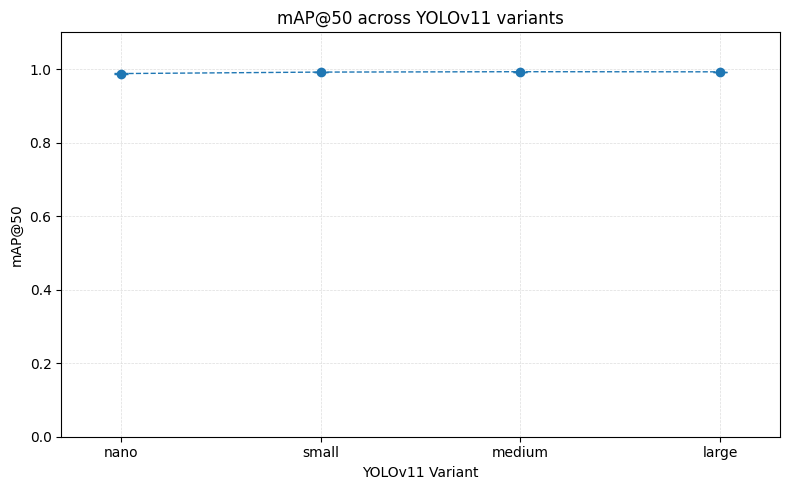

In [7]:
plot_global_metric(
    column_name = 'mAP50', y_label = "mAP@50",
    title = "mAP@50 across YOLOv11 variants",
    verbose = True,
)

#### 2.A.2 mAP@50-95
<span id="plot_map_50_95"></span>

Variant nano:
    Values: [0.823, 0.820, 0.818, 0.847, 0.784]
    Mean: 0.819,   CI(95.0%): 0.025
Variant small:
    Values: [0.909, 0.920, 0.918, 0.913, 0.919]
    Mean: 0.916,   CI(95.0%): 0.005
Variant medium:
    Values: [0.935, 0.948, 0.945, 0.948, 0.946]
    Mean: 0.944,   CI(95.0%): 0.006
Variant large:
    Values: [0.951, 0.948, 0.948, 0.947, 0.950]
    Mean: 0.949,   CI(95.0%): 0.002
Image save to: comparison_plots/map_50_95_across_yolov11_variants.png


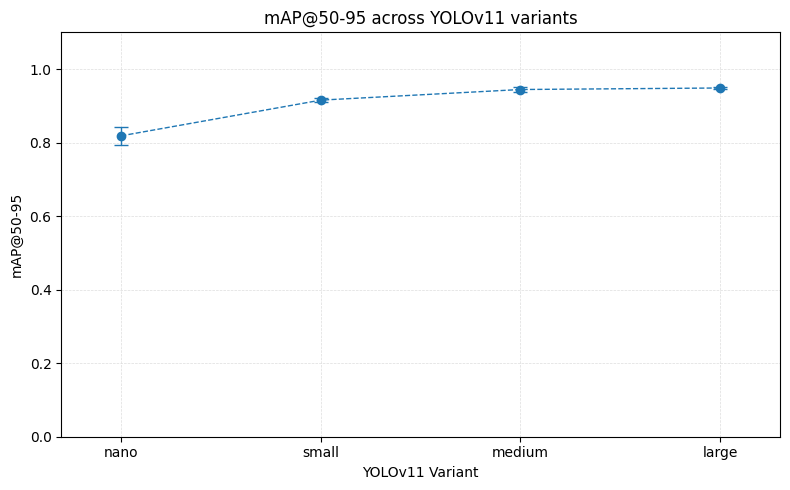

In [8]:
plot_global_metric(
    column_name = 'mAP50-95', y_label = "mAP@50-95",
    title = "mAP@50-95 across YOLOv11 variants",
    verbose = True
)

### 2.B Accuracy metrics by group

#### 2.B.0 Groups

##### Groups definitions
A group of classes is identified by the list of the class indexes

In [9]:
CLASSES__GBY_ALL = {
    "all":    range(0, 52, 1)
}

In [10]:
CLASSES__GBY_SUIT = {
    "clubs":    range(0, 52, 4),
    "diamonds": range(1, 52, 4),
    "hearts":   range(2, 52, 4),
    "spades":   range(3, 52, 4),
}

In [11]:
CLASSES__GBY_RANK = {
    "A":  range(36, 40),
    "2":  range(4,  8),
    "3":  range(8,  12),
    "4":  range(12, 16),
    "5":  range(16, 20),
    "6":  range(20, 24),
    "7":  range(24, 28),
    "8":  range(28, 32),
    "9":  range(32, 36),
    "10": range(0,  4),
    "J":  range(40, 44),
    "Q":  range(48, 52),
    "K":  range(44, 48),
}

In [12]:
CLASSES__GBY_TYPE = {
    "number": range(0, 40),
    "figure": range(40, 52),
}

##### Custom colors definition

In [13]:
# ===== Colors by suit

COLORS__GBY_SUIT = {
    "clubs":    "#1B5E20",
    "diamonds": "#D84315",
    "hearts":   "#B71C1C",
    "spades":   "#212121",
}

In [14]:
# ===== Colors by rank

COLORS__GBY_RANK = {
    "A":  "#FFD700",
    "2":  "#E41A1C",
    "3":  "#377EB8",
    "4":  "#4DAF4A",
    "5":  "#984EA3",
    "6":  "#FF7F00",
    "7":  "#A65628",
    "8":  "#00BFFF",
    "9":  "#F781BF",
    "10": "#999999",
    "J":  "#66C2A5",
    "Q":  "#FC8D62",
    "K":  "#A6D854",
}

In [15]:
# ===== Colors by type

COLORS__GBY_TYPE = {
    "number": "#1F77B4",
    "figure": "#FF7F0E",
}

#### 2.B.1 Utility functions

##### ***plot_metric_grouped***

Plot metrics given class-by-class by YOLO during model evaluation.

With the function `plot_metric_grouped` we can plot:
- mAP@50-95 : set `column_name = 'mAP50-95'`
- Precision : set `column_name = 'precision'`
- Recall : set `column_name = 'recall'`
- F1 Score : set `column_name = 'f1'`

Any group can be defined, the predifined and used ones are:
- Group by suit (♣, ♦, ♥, ♠): set `groups = CLASSES__GBY_SUIT`
- Group by rank (A, 2, 3, 4, 5, 6, 7, 8, 9, 10, J, Q, K): set `groups = CLASSES__GBY_RANK`
- Group by type (figure or number): set `groups = CLASSES__GBY_TYPE`

In [16]:
# ===== plot_metric_grouped function

def plot_metric_grouped(
    column_name,
    groups,
    colors = None,
    ci_perc: float = 0.95,
    y_label: str = None,
    title: str = None,
    y_bottom: float = 0.0,
    y_top: float = 1.1,
    figsize=(8, 5),
    verbose: bool = False,
):
    
    x_ticks = VARIANTS

    means = []
    cis = []
    group_items = list(groups.items())

    # Loop over every group to get a mean line for each group
    for group_name, class_idxs in group_items:

        group_means = []
        group_cis = []

        # Loop over the variant
        for variant in VARIANTS:

            fold_values = []

            # Loop over all folds
            for fold_idx in FOLDS:

                if fold_idx not in RESULTS_TABLE[variant]:
                    continue

                # Get metric value for current variant and fold
                values = np.asarray(
                    RESULTS_TABLE[variant][fold_idx][column_name]
                )

                # Append to list of fold values
                fold_values.append(values[list(class_idxs)].mean())
            
            # Convert to np array
            fold_values = np.asarray(fold_values)

            # Extract statistic indexes
            mean, _, ci_err = mean_std_ci(fold_values, ci_perc)

            # Append statistic to the group array
            group_means.append(mean)
            group_cis.append(ci_err)
            
            # Debug printing
            if verbose:
                print(f"Variant {variant}:")
                print(f"    Values: [{', '.join(f'{v:.3f}' for v in fold_values)}]")
                print(f"    Mean: {mean:.3f},   CI ({ci_perc*100}%): {ci_err:.3f}")

        # Append group result (what will become a single line) to global arrays
        means.append(group_means)
        cis.append(group_cis)

    # Convert to numpy
    means = np.asarray(means)
    cis = np.asarray(cis)

    # Construct colors array
    group_names = list(groups.keys())
    if isinstance(colors, dict):
        colors = [colors[g] for g in group_names]

    if len(group_names) > 1:
        labels = group_names
    else:
        labels = None

    # Plot
    plot(
        x_ticks=x_ticks,
        means=means,
        cis=cis,
        colors=colors,
        figsize=figsize,
        y_bottom=y_bottom,
        y_top=y_top,
        y_label=y_label,
        title=title,
        line_labels=labels,

        plot__ci_t = True,
        plot__ci_band = False
    )

#### 2.B.2 Group by All
Metrics such as precision, recall and f1-score are only given class by class: if we need a single metric for a given model we can use the `plot_metric_grouped` function to work around this, just via grouping all classes together.

##### Precision
<span id="plot_precision"></span>

Variant nano:
    Values: [0.958, 0.965, 0.963, 0.957, 0.950]
    Mean: 0.959,   CI (95.0%): 0.006
Variant small:
    Values: [0.980, 0.979, 0.978, 0.978, 0.979]
    Mean: 0.979,   CI (95.0%): 0.001
Variant medium:
    Values: [0.985, 0.984, 0.986, 0.988, 0.984]
    Mean: 0.985,   CI (95.0%): 0.002
Variant large:
    Values: [0.986, 0.988, 0.989, 0.986, 0.989]
    Mean: 0.988,   CI (95.0%): 0.002
Image save to: comparison_plots/precision_across_yolov11_variants.png


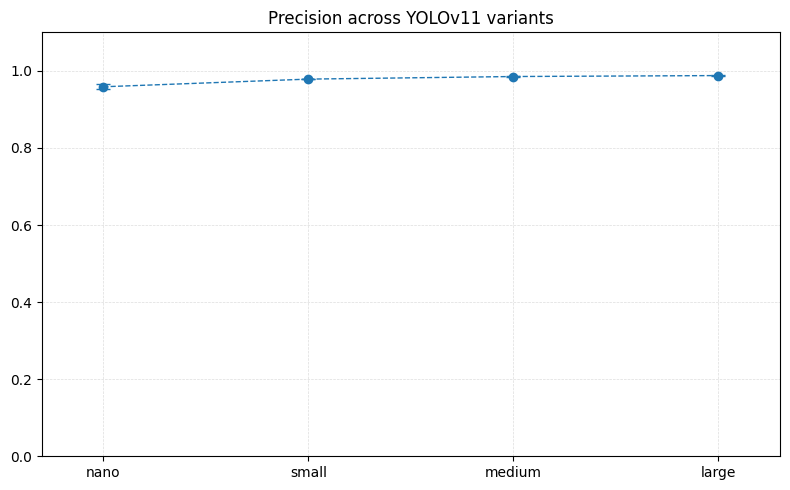

In [17]:
plot_metric_grouped(
    column_name="precision",
    groups=CLASSES__GBY_ALL,
    title="Precision across YOLOv11 variants",
    verbose=True
)

##### Recall
<span id="plot_recall"></span>

Variant nano:
    Values: [0.988, 0.982, 0.978, 0.996, 0.985]
    Mean: 0.986,   CI (95.0%): 0.007
Variant small:
    Values: [0.991, 0.992, 0.994, 0.990, 0.989]
    Mean: 0.991,   CI (95.0%): 0.002
Variant medium:
    Values: [0.993, 0.994, 0.992, 0.991, 0.991]
    Mean: 0.992,   CI (95.0%): 0.001
Variant large:
    Values: [0.989, 0.987, 0.989, 0.986, 0.986]
    Mean: 0.987,   CI (95.0%): 0.002
Image save to: comparison_plots/recall_across_yolov11_variants.png


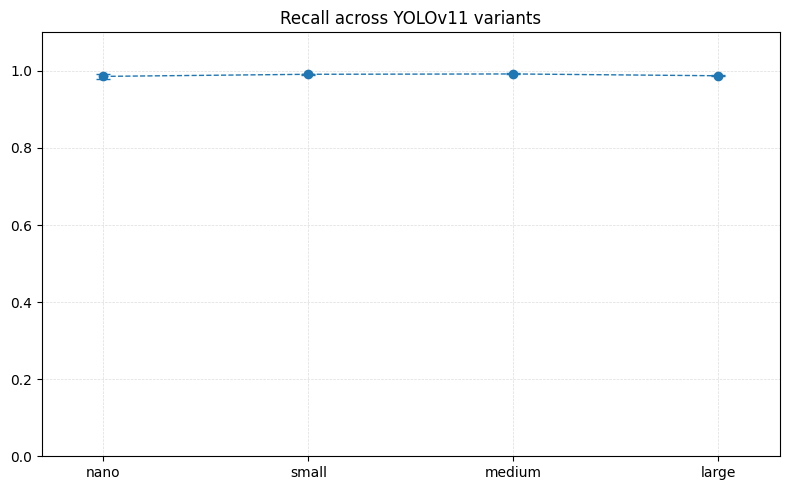

In [18]:
plot_metric_grouped(
    column_name="recall",
    groups=CLASSES__GBY_ALL,
    title="Recall across YOLOv11 variants",
    verbose=True
)

##### F1 Score
<span id="plot_f1_score"></span>

Variant nano:
    Values: [0.972, 0.973, 0.970, 0.974, 0.966]
    Mean: 0.971,   CI (95.0%): 0.004
Variant small:
    Values: [0.985, 0.985, 0.986, 0.984, 0.984]
    Mean: 0.985,   CI (95.0%): 0.001
Variant medium:
    Values: [0.989, 0.989, 0.989, 0.989, 0.987]
    Mean: 0.989,   CI (95.0%): 0.001
Variant large:
    Values: [0.987, 0.987, 0.989, 0.986, 0.987]
    Mean: 0.988,   CI (95.0%): 0.001
Image save to: comparison_plots/f1_score_across_yolov11_variants.png


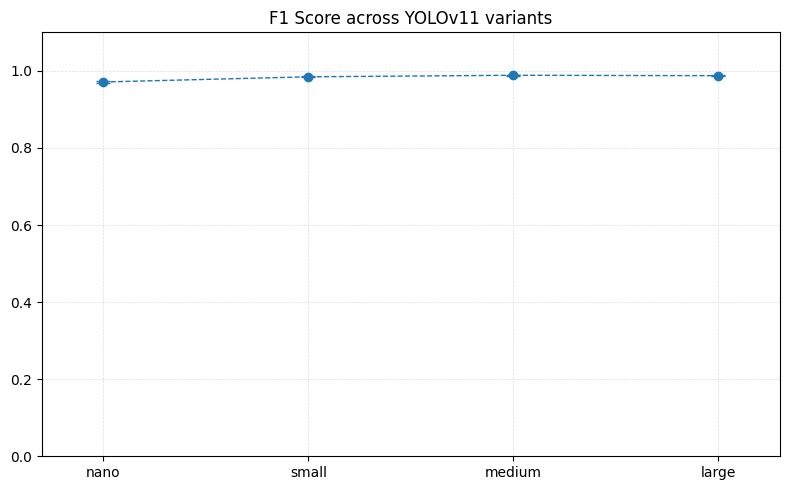

In [19]:
plot_metric_grouped(
    column_name="f1",
    groups=CLASSES__GBY_ALL,
    title="F1 Score across YOLOv11 variants",
    verbose=True
)

#### 2.B.3 Group by Suit

##### mAP50@95

Image save to: comparison_plots/map_50_95_by_suit.png


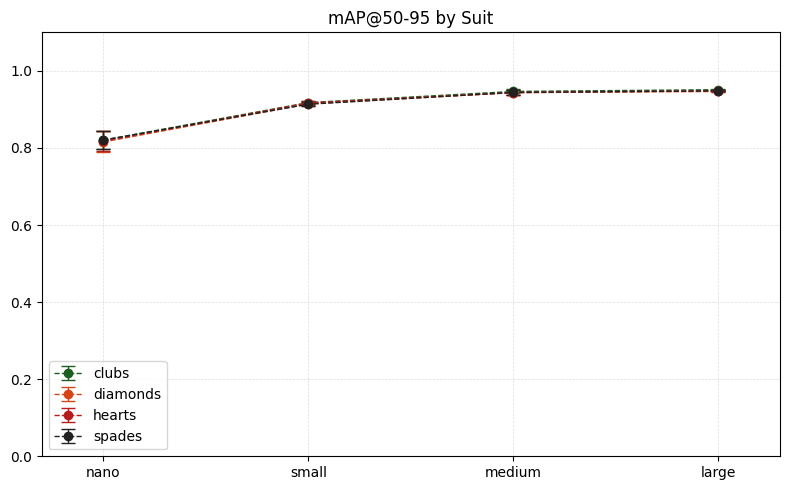

In [20]:
plot_metric_grouped(
    column_name="mAP50-95_per_class",
    groups=CLASSES__GBY_SUIT,
    colors=COLORS__GBY_SUIT,
    title="mAP@50-95 by Suit"
)

##### Precision

Image save to: comparison_plots/precision_by_suit.png


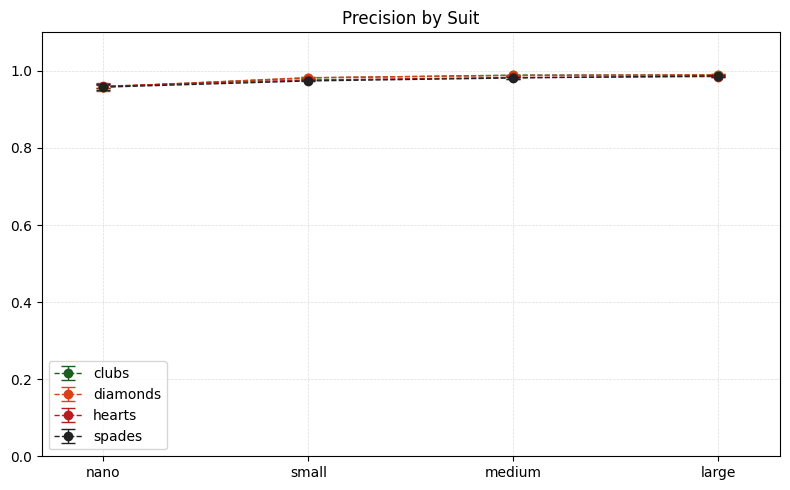

In [21]:
plot_metric_grouped(
    column_name="precision",
    groups=CLASSES__GBY_SUIT,
    colors=COLORS__GBY_SUIT,
    title="Precision by Suit"
)

##### Recall

Image save to: comparison_plots/recall_by_suit.png


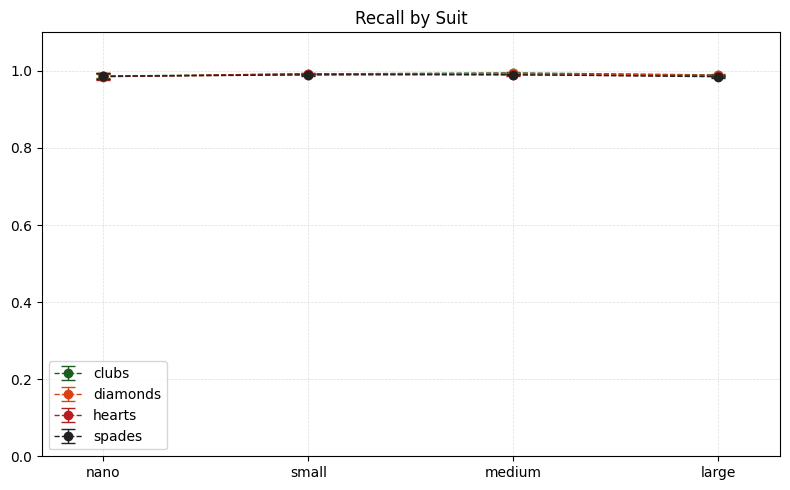

In [22]:
plot_metric_grouped(
    column_name="recall",
    groups=CLASSES__GBY_SUIT,
    colors=COLORS__GBY_SUIT,
    title="Recall by Suit"
)

##### F1 Score

Image save to: comparison_plots/f1_score_by_suit.png


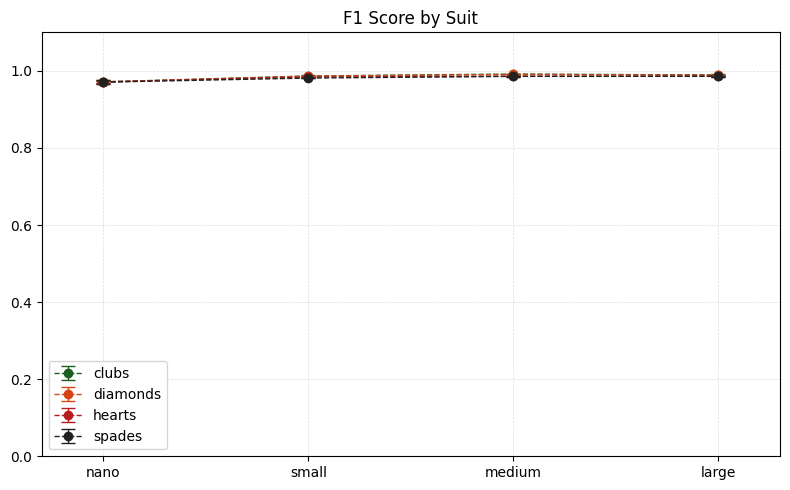

In [23]:
plot_metric_grouped(
    column_name="f1",
    groups=CLASSES__GBY_SUIT,
    colors=COLORS__GBY_SUIT,
    title="F1 Score by Suit"
)

#### 2.B.4 Group by Rank

##### map@50-95

Image save to: comparison_plots/map_50_95_by_rank.png


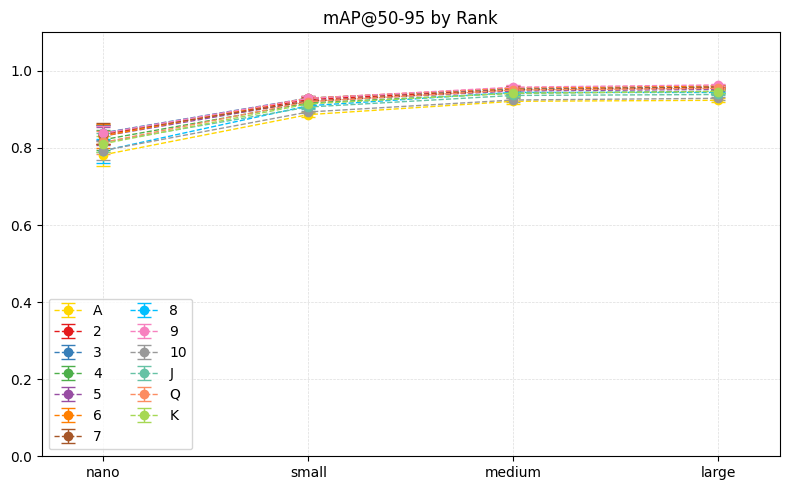

In [24]:
plot_metric_grouped(
    column_name="mAP50-95_per_class",
    groups=CLASSES__GBY_RANK,
    colors=COLORS__GBY_RANK,
    title="mAP@50-95 by Rank",
    # y_bottom=0.7 # uncomment to zoom in
)

##### Precision

Image save to: comparison_plots/precision_by_rank.png


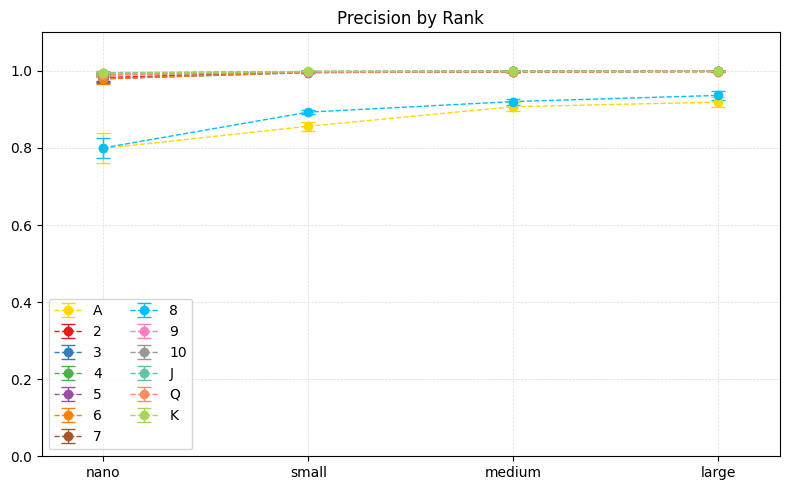

In [25]:
plot_metric_grouped(
    column_name="precision",
    groups=CLASSES__GBY_RANK,
    colors=COLORS__GBY_RANK,
    title="Precision by Rank",
    # y_bottom=0.7 # uncomment to zoom in
)

##### Recall

Image save to: comparison_plots/recall_by_rank.png


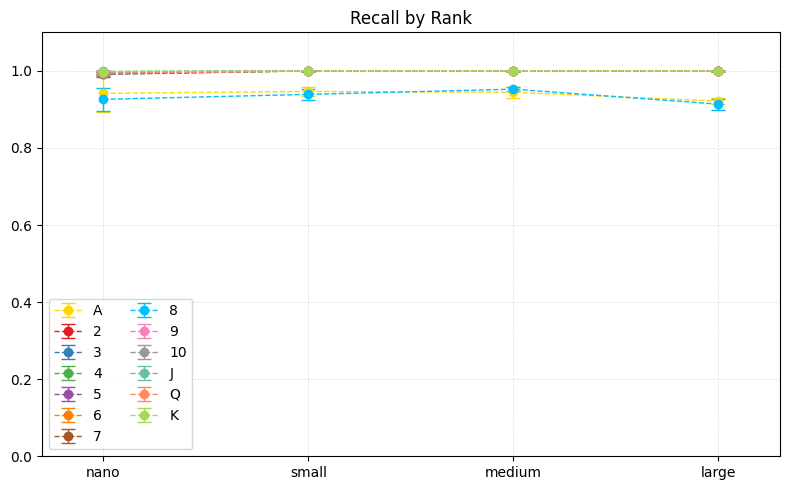

In [26]:
plot_metric_grouped(
    column_name="recall",
    groups=CLASSES__GBY_RANK,
    colors=COLORS__GBY_RANK,
    title="Recall by Rank",
    # y_bottom=0.7 # uncomment to zoom in
)

##### F1 Score

Image save to: comparison_plots/f1_score_by_rank.png


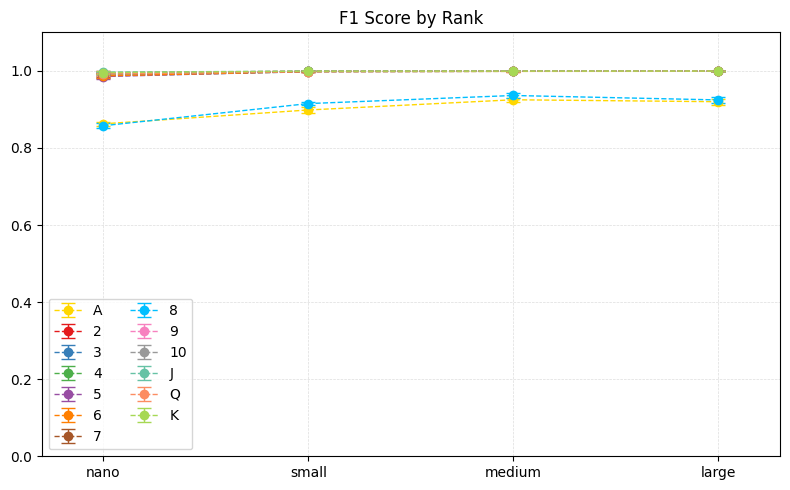

In [27]:
plot_metric_grouped(
    column_name="f1",
    groups=CLASSES__GBY_RANK,
    colors=COLORS__GBY_RANK,
    title="F1 Score by Rank",
    # y_bottom=0.7 # uncomment to zoom in
)

#### 2.B.5 Group by Type

##### mAP@50-95

Image save to: comparison_plots/map_50_95_by_type_number_figure.png


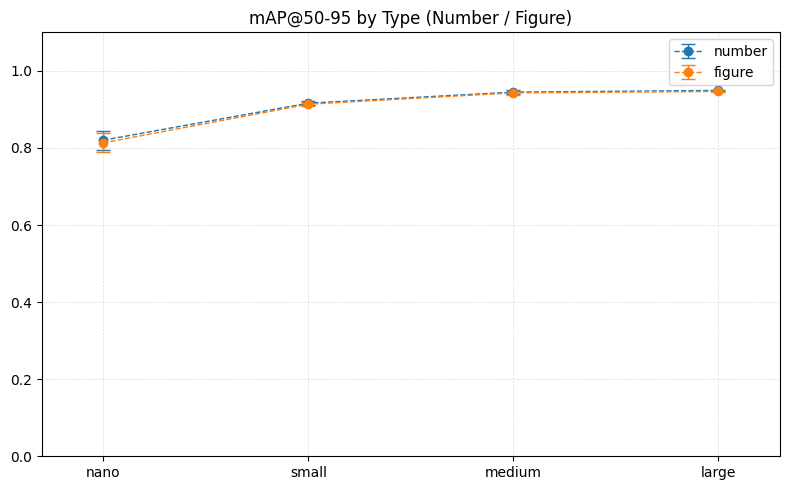

In [28]:
plot_metric_grouped(
    column_name="mAP50-95_per_class",
    groups=CLASSES__GBY_TYPE,
    colors=COLORS__GBY_TYPE,
    title="mAP@50-95 by Type (Number / Figure)",
    # y_bottom=0.7 # uncomment to zoom in
)

##### Precision

Image save to: comparison_plots/precision_by_type_number_figure.png


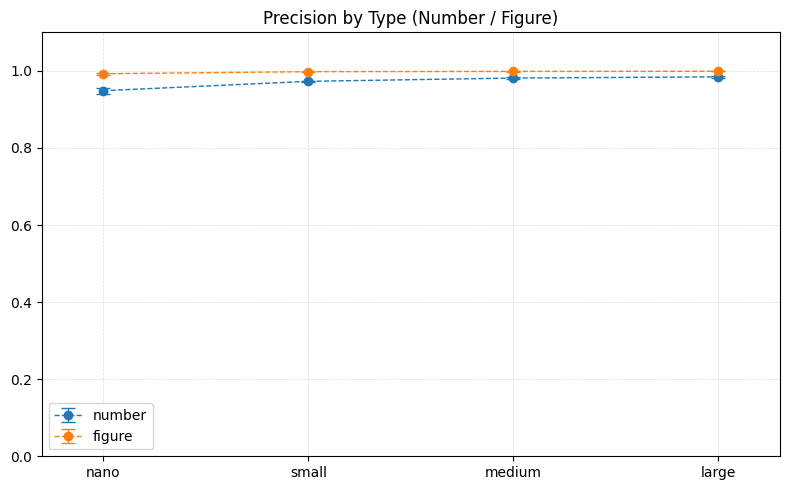

In [29]:
plot_metric_grouped(
    column_name="precision",
    groups=CLASSES__GBY_TYPE,
    colors=COLORS__GBY_TYPE,
    title="Precision by Type (Number / Figure)",
    # y_bottom=0.7 # uncomment to zoom in
)

##### Recall

Image save to: comparison_plots/recall_by_type_number_figure.png


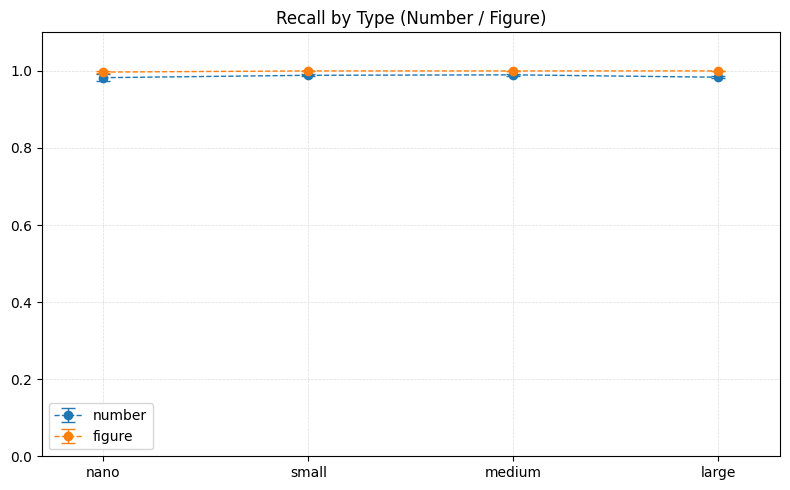

In [30]:
plot_metric_grouped(
    column_name="recall",
    groups=CLASSES__GBY_TYPE,
    colors=COLORS__GBY_TYPE,
    title="Recall by Type (Number / Figure)",
    # y_bottom=0.7 # uncomment to zoom in
)

##### F1 Score

Image save to: comparison_plots/f1_score_by_type_number_figure.png


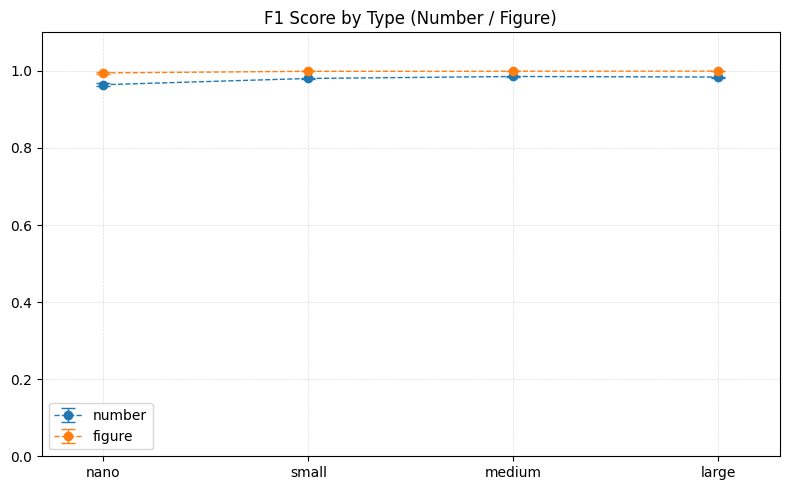

In [31]:
plot_metric_grouped(
    column_name="f1",
    groups=CLASSES__GBY_TYPE,
    colors=COLORS__GBY_TYPE,
    title="F1 Score by Type (Number / Figure)",
    # y_bottom=0.7 # uncomment to zoom in
)

### 2.C Inference times

#### 2.C.0 Utility functions

##### Get GPU / CPU names

In [32]:
# ===== Get CPU and GPU names

import subprocess

def get_cpu_model():
    with open("/proc/cpuinfo", "r") as f:
        for line in f:
            if "model name" in line:
                return line.split(":")[1].strip()
    return None

def get_gpu_model():
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            text=True
        )
        return out.strip()
    except Exception:
        return None

##### Measure inference time function

In [33]:
# ===== measure_inference_times function

import time
import glob
import numpy as np
from ultralytics import YOLO

def measure_inference_times(
    model_path, N, device,
    image_folder = '/workspace/datasets/pcd_merge_kfcv/images', 
):
    
    # Get model
    model = YOLO(model_path, task="detect")

    # Get images ref
    images = glob.glob(f"{image_folder}/*.jpg")
    if len(images) == 0:
        raise ValueError("Nessuna immagine trovata nella cartella")

    # warm-up
    for _ in range(10):
        model.predict(images[0], device=device, verbose=False)

    times = []
    
    # Measure the inference time over N images
    for i in range(N):
        img = images[i % len(images)]

        start = time.perf_counter()
        _ = model.predict(img, device=device, verbose=False)
        end = time.perf_counter()

        times.append(end - start)

    # return array of times in seconds
    return np.array(times)

##### Measure and plot inference times
Loads the model, perfom N inferences, track their times, plot

In [34]:
# ===== measure_and_plot_inference_times function

import matplotlib.pyplot as plt

def measure_and_plot_inference_times(
    device: str | int,
    plot_fps = False,
    img_per_var: int = 25,
    ci_perc: float = 0.95,
    y_label: str = None,
    title: str = None,
    verbose: bool = False
):
    # Get mean values and confidence intervals
    means = []
    cis = []
    
    for variant in VARIANTS:

        var_times = []

        for fold_idx in FOLDS:

            _, model_path, _ = model_directory(variant, fold_idx)
    
            model_path = model_path / "best.pt"
            
            if not model_path.is_file():
                print(f"skipping {variant}/fold_{fold_idx}")
                continue
    
            # Measure inference time for N times
            fold_times = measure_inference_times(
                model_path = model_path, 
                device = device,
                N = img_per_var // len(FOLDS)
            )

            var_times.extend(fold_times)

        var_times = np.array(var_times)

        # If FPS ties are already in seconds
        if plot_fps:
            values_to_plot = 1 / var_times
            
        # Else convert to ms
        else:
            values_to_plot = 1000 * var_times

        # Extract stats
        mean, _, ci_err = mean_std_ci(values_to_plot, ci_perc)

        # Save results
        means.append(mean)
        cis.append(ci_err)

        if verbose:
            print(f"Variant {variant}:")
            # print(f"    Values: [{', '.join(f'{v:.3f}' for v in values_to_plot)}]")
            print(f"    Mean: {mean:.3f},   CI({ci_perc*100}%): {ci_err:.3f}")

    # 2) plot
    plot(
        x_ticks = VARIANTS,
        means = np.array(means),
        cis = np.array(cis),

        plot__ci_t = True,
        plot__ci_band = False,
        
        y_bottom = 0,

        y_label = y_label,
        x_label = "YOLOv11 Variant",
        title = title
    )

##### Plot timings per variant
Plot timing values given in results.json, without the need to infer the model again.

All the timing values are under the field `speed` (hence a new function is here defined), some values avialable are:
- `preproces`
- `inference`
- `postprocess`

In the function all column passed in `column_names` will be summed up, so that a total time can be plotted

In [35]:
# ===== plot_times_per_variant function

import matplotlib.pyplot as plt

def plot_times_per_variant(
    column_names = ['preprocess', 'inference', 'postprocess', 'loss'],
    plot_fps = False,
    ci_perc: float = 0.95,
    y_label: str = None,
    title: str = None,
    y_bottom: float = 0.0,
    verbose: bool = False,
):

    # 1) Retrieve values to plot

    # Get mean values and confidence intervals
    means = []
    cis = []
    
    for variant in VARIANTS:

        target_values = [

            sum(
                # select the target column
                np.asarray(RESULTS_TABLE[variant][fold_idx]['speed'][c])
                for c in column_names
            )

            # for all folds
            for fold_idx in FOLDS
            
            if fold_idx in RESULTS_TABLE[variant]
        ]

        target_values = np.array(target_values)
        
        if plot_fps:
            target_values = 1000.0 / target_values
        
        mean, _, ci_val = mean_std_ci(target_values, ci_perc)
        means.append(mean)
        cis.append(ci_val)

        if verbose:
            print(f"Variant {variant}:")
            print(f"    Values: [{', '.join(f'{v:.3f}' for v in target_values)}]")
            print(f"    Mean: {mean:.3f},   CI({ci_perc*100}%): {ci_val:.3f}")
    
    means = np.array(means)
    cis = np.array(cis)

    # get x values indexes
    x = np.arange(len(VARIANTS))


    plot(
        x_ticks = VARIANTS,
        means = means,
        cis = cis,
        
        plot__ci_t = True,
        plot__ci_band = False,

        y_bottom = y_bottom,

        y_label = y_label,
        x_label = "YOLOv11 Variant",
        title = title
    )

#### 2.C.1 Inference time on CPU
<span id="plot_inference_cpu"></span>

/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Variant nano:
    Mean: 37.408,   CI(95.0%): 0.781
Variant small:
    Mean: 55.657,   CI(95.0%): 2.255
Variant medium:
    Mean: 116.137,   CI(95.0%): 2.012
Variant large:
    Mean: 140.620,   CI(95.0%): 5.007
Image save to: comparison_plots/mean_inference_time_across_yolov11_variants_on_cpu_intel_r_xeon_r_platinum_8480.png


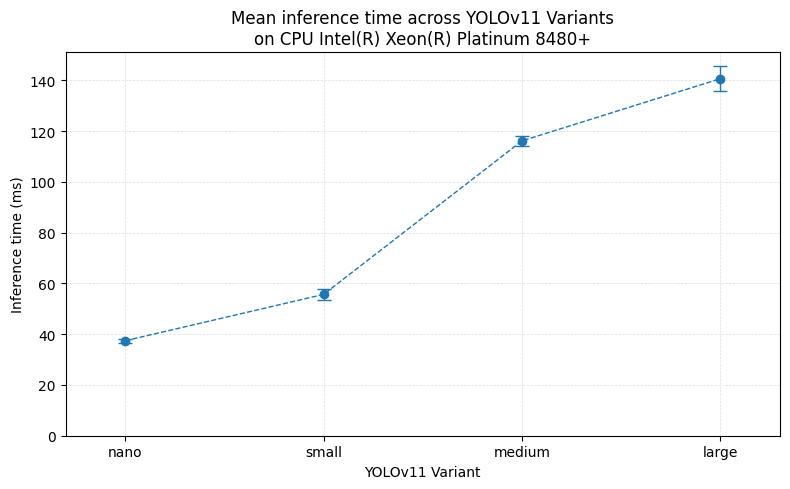

In [36]:
measure_and_plot_inference_times(
    device = 'cpu', y_label = "Inference time (ms)", 
    title = f"Mean inference time across YOLOv11 Variants\non CPU {get_cpu_model()}",
    verbose = True,
)

/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Variant nano:
    Mean: 33.173,   CI(95.0%): 0.378
Variant small:
    Mean: 20.881,   CI(95.0%): 0.287
Variant medium:
    Mean: 10.359,   CI(95.0%): 0.242
Variant large:
    Mean: 7.620,   CI(95.0%): 0.240
Image save to: comparison_plots/mean_latency_across_yolov11_variants_on_cpu_intel_r_xeon_r_platinum_8480.png


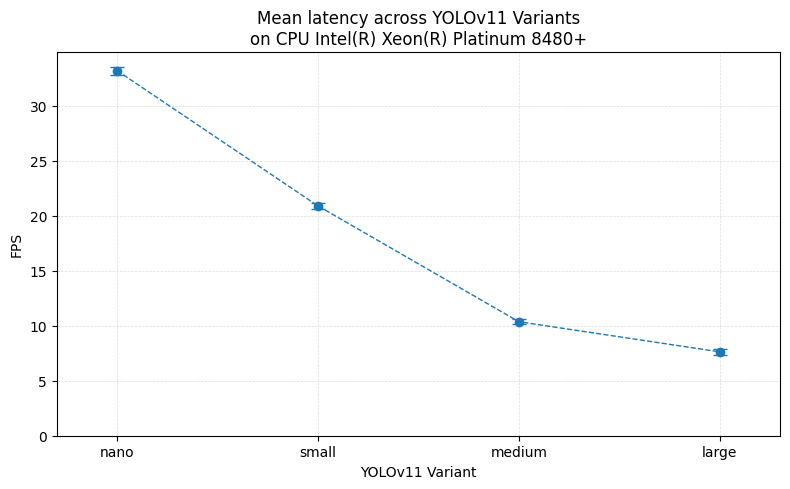

In [37]:
measure_and_plot_inference_times(
    device = 'cpu', y_label = "FPS", plot_fps = True,
    title = f"Mean latency across YOLOv11 Variants\non CPU {get_cpu_model()}",
    verbose = True
)

#### 2.C.2 Inference time on GPU
<span id="plot_inference_time"></span>

Variant nano:
    Values: [0.604, 0.511, 0.520, 0.517, 0.531]
    Mean: 0.537,   CI(95.0%): 0.043
Variant small:
    Values: [0.813, 0.788, 0.812, 0.790, 0.786]
    Mean: 0.798,   CI(95.0%): 0.015
Variant medium:
    Values: [1.604, 1.596, 1.594, 1.588, 1.595]
    Mean: 1.595,   CI(95.0%): 0.007
Variant large:
    Values: [2.095, 2.090, 2.088, 2.091, 2.096]
    Mean: 2.092,   CI(95.0%): 0.004
Image save to: comparison_plots/mean_inference_time_across_yolov11_variants_on_gpu_none.png


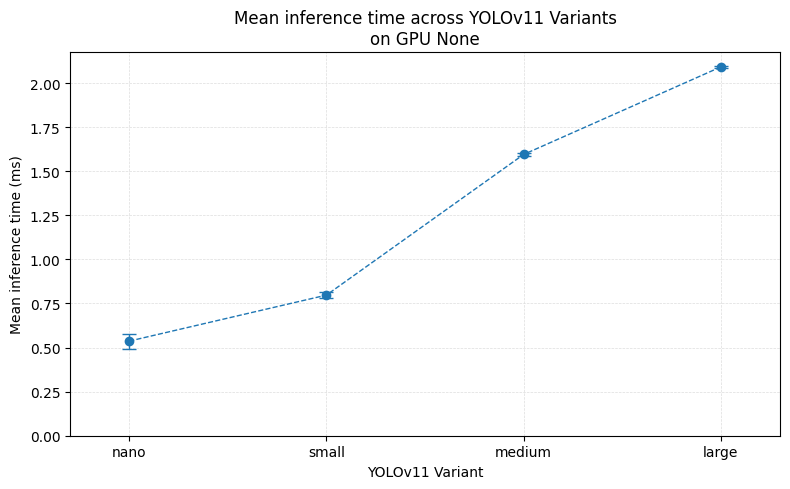

In [38]:
plot_times_per_variant(
    column_names = ['inference'], y_label = "Mean inference time (ms)",
    title = f"Mean inference time across YOLOv11 Variants\non GPU {get_gpu_model()}",
    verbose = True
)

Variant nano:
    Values: [1.279, 1.148, 1.172, 1.155, 1.174]
    Mean: 1.185,   CI(95.0%): 0.059
Variant small:
    Values: [1.460, 1.422, 1.454, 1.400, 1.407]
    Mean: 1.429,   CI(95.0%): 0.030
Variant medium:
    Values: [2.229, 2.218, 2.217, 2.190, 2.206]
    Mean: 2.212,   CI(95.0%): 0.016
Variant large:
    Values: [2.718, 2.701, 2.727, 2.701, 2.739]
    Mean: 2.717,   CI(95.0%): 0.018
Image save to: comparison_plots/mean_total_latency_across_yolov11_variants_on_gpu_none.png


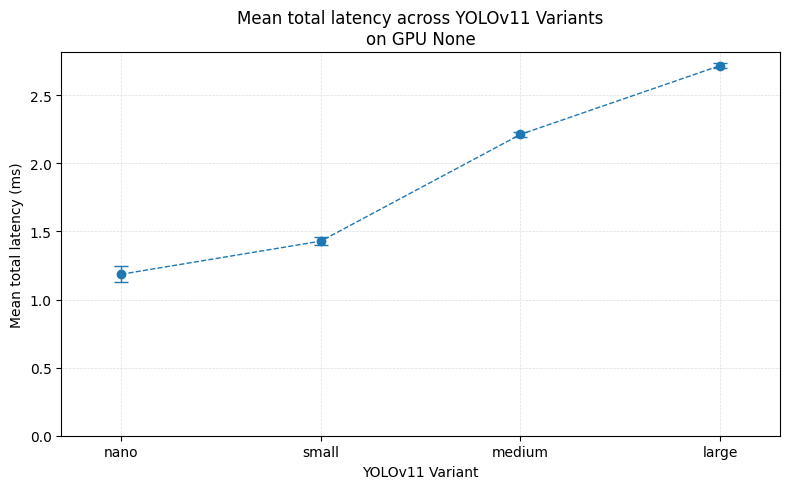

In [39]:
plot_times_per_variant(
    y_label = "Mean total latency (ms)",
    title = f"Mean total latency across YOLOv11 Variants\non GPU {get_gpu_model()}",
    verbose = True
)

Variant nano:
    Values: [782.101, 871.113, 853.123, 866.041, 852.000]
    Mean: 844.876,   CI(95.0%): 40.026
Variant small:
    Values: [685.023, 703.326, 687.532, 714.200, 710.967]
    Mean: 700.210,   CI(95.0%): 14.822
Variant medium:
    Values: [448.552, 450.925, 451.116, 456.641, 453.220]
    Mean: 452.091,   CI(95.0%): 3.369
Variant large:
    Values: [367.879, 370.216, 366.695, 370.256, 365.108]
    Mean: 368.031,   CI(95.0%): 2.488
Image save to: comparison_plots/mean_fps_across_yolov11_variants_on_gpu_none.png


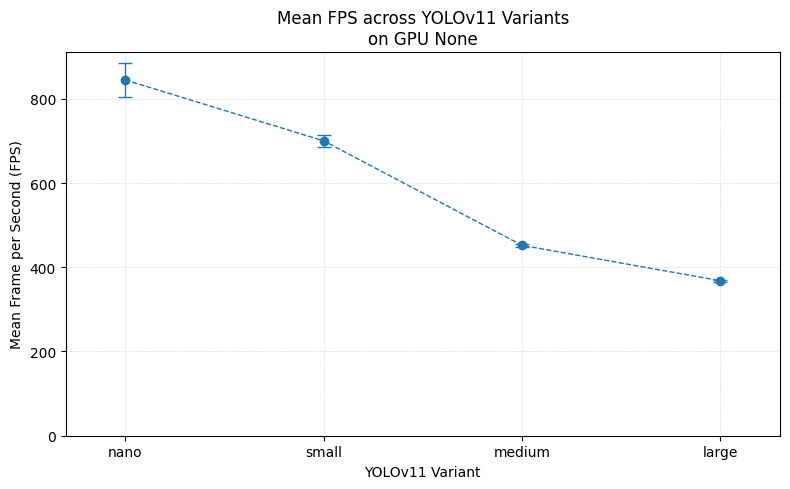

In [40]:
plot_times_per_variant(
    y_label = "Mean Frame per Second (FPS)", plot_fps = True,
    title = f"Mean FPS across YOLOv11 Variants\non GPU {get_gpu_model()}",
    verbose = True
)

### 2.D Memory footprint

#### 2.D.0 Utility functions

##### Dimension conversion

In [41]:
def get_unit_conversion_and_name(unit: str):
    """ Returns conversion_factor, unit_name """
    if unit == "KiB":
        return 1024, "KiB"
    elif unit == "MiB":
        return 1048576, "MiB"
    elif unit == "GiB":
        return 1073741824, "GiB"
    else:
        return 1, "Bytes"


##### Model dimention plot function

In [42]:
# ===== plot_inference_times function
import os
import matplotlib.pyplot as plt

def plot_model_dimensions(
    ci_perc: float = 0.95,
    unit: str = "MiB",
    y_label: str = None,
    title: str = None,
    verbose: bool = False
):
    # Get unit conversion factor and unit name
    unit_conv, unit_name = get_unit_conversion_and_name(unit)
    
    # Get mean values and confidence intervals
    means = []
    cis = []
        
    for variant in VARIANTS:

        variant_sizes = []

        for fold_idx in FOLDS:

            _, model_path, _ = model_directory(variant, 0)
    
            model_path = model_path / "best.pt"
    
            # Get model dimension
            model_size = float(os.path.getsize(model_path))

            # Convert to chosen unit
            model_size = model_size / unit_conv

            variant_sizes.append(model_size)

        # Extract stats
        variant_sizes = np.array(variant_sizes)
        mean, _, ci_err = mean_std_ci(variant_sizes, ci_perc)

        # Save results
        means.append(mean)
        cis.append(ci_err)

        if verbose:
            print(f"Variant {variant}:")
            print(f"    Values: [{', '.join(f'{v:.3f}' for v in variant_sizes)}]")
            print(f"    Mean: {mean:.3f},   CI({ci_perc*100}%): {ci_err:.3f}")

    means = np.array(means)
    cis = np.array(cis)

    # 2) plot
    plot(
        x_ticks = VARIANTS,
        means = means,
        cis = cis,

        plot__ci_t = True,
        plot__ci_band = False,
        
        y_bottom = 0,

        y_label = y_label + f" ({unit_name})",
        x_label = "YOLOv11 Variant",
        title = title
    )

#### 2.D.1 Dimension plot
<span id="plot_dimension"></span>

Variant nano:
    Values: [5.251, 5.251, 5.251, 5.251, 5.251]
    Mean: 5.251,   CI(95.0%): 0.000
Variant small:
    Values: [18.349, 18.349, 18.349, 18.349, 18.349]
    Mean: 18.349,   CI(95.0%): 0.000
Variant medium:
    Values: [38.734, 38.734, 38.734, 38.734, 38.734]
    Mean: 38.734,   CI(95.0%): 0.000
Variant large:
    Values: [48.921, 48.921, 48.921, 48.921, 48.921]
    Mean: 48.921,   CI(95.0%): 0.000
Image save to: comparison_plots/model_dimension_across_yolov11_variants.png


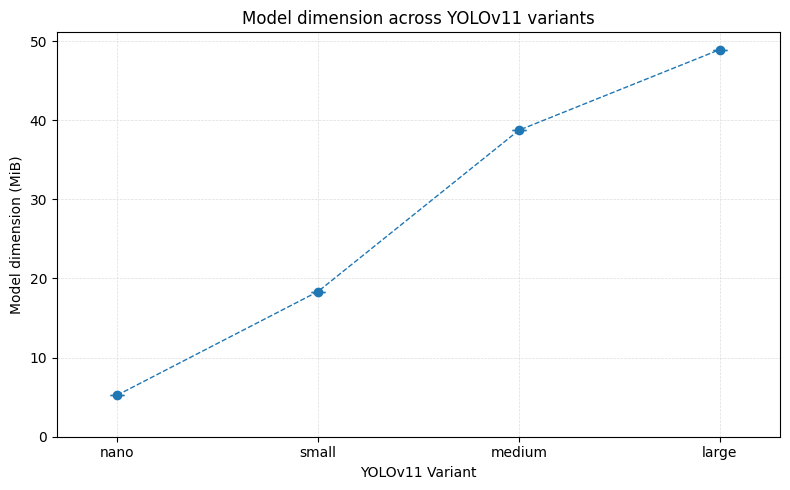

In [43]:
plot_model_dimensions(
    ci_perc = 0.95, unit="MiB",
    y_label = "Model dimension",
    title = "Model dimension across YOLOv11 variants",
    verbose = True
)

## 3. Final evaluation

Given:
- Accuracy results [(2.A.2) mAP@50](#plot_map_50), [(2.A.2) mAP@50-95](#plot_map_50_95), [(2.B.2) Precision](#plot_precision), [(2.B.2) Recall](#plot_recall), [(2.B.2) F1 Score](#plot_f1_score)
- Inference time / Latency [(2.C.1) Inference time on CPU](#plot_inference_cpu)
- Dimension of the model [(2.D.1) Dimension Plot](#plot_dimension)

We found the **small** variant to be the most suitable for our purposes